# Calibración y rectificación estéreo

Este notebook **calibra desde las imágenes de `data/calibration`**. Detecta el
checkerboard, estima los parámetros de ambas cámaras y su transformación relativa,
valida el resultado y guarda los archivos que consume el notebook 02.
Los `.pkl` anteriores no intervienen en la estimación.

## Checkerboard usado

| Parámetro | Valor |
|---|---|
| Esquinas internas (columnas × filas) | 9 × 6 (54 puntos) |
| Cantidad de cuadrados (columnas × filas) | 10 × 7 |
| Lado configurado de cada cuadrado | 28 mm |
| Tamaño del patrón, sin márgenes | 280 × 196 mm |

El lado físico del cuadrado fija la escala de `T` y de las nubes obtenidas con `Q`.
La configuración usa 28 mm; confirmar esta medida en el tablero impreso antes de
reportar dimensiones del objeto.

In [8]:
import sys
from pathlib import Path

# Funciona con el kernel iniciado desde la raíz o desde notebooks/.
ROOT_DIR = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src").is_dir() and (directory / "data").is_dir()
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

## 1. Configuración y pares de calibración

In [9]:
from src.utils.prints import print_calibration_results, print_calibration_diagnostics
from src.utils.plotting import show_calibration_errors, show_rectification_example
from src.calibration_rectification import (
    load_calibration_data,
    save_calibration_results,
    calibrate_and_evaluate,
)

CALIBRATION_IMAGES_DIR = ROOT_DIR / "data/calibration"
CALIBRATION_DIR = ROOT_DIR / "data/calibration_results"
REPORT_IMAGES_DIR = ROOT_DIR / "report/report_images"
COLS, ROWS = 9, 6
SQUARE_SIZE_MM = 28.0
RECTIFICATION_ALPHA = 0.0
TAU_PX = 3
MAX_CALIB_ITER = 100

In [10]:
calibration_data = load_calibration_data(
    CALIBRATION_IMAGES_DIR, square_size=SQUARE_SIZE_MM, rows=ROWS, cols=COLS
)
image_size = calibration_data["image_size"]
print(f"Tamaño por cámara: {image_size} px (ancho, alto)")
print(
    f"Pares con tablero detectado: {len(calibration_data['used_pair_ids'])} / {len(calibration_data['pair_ids'])}"
)
print(
    f"Índices descartados sin detección en ambas cámaras: {calibration_data['rejected_pair_ids']}"
)

Tamaño por cámara: (1920, 1080) px (ancho, alto)
Pares con tablero detectado: 47 / 63
Índices descartados sin detección en ambas cámaras: [6, 7, 9, 29, 30, 31, 32, 47, 48, 49, 50, 51, 56, 57, 58, 61]


## 2. Calibración monocular y estéreo; rectificación y evaluación

In [11]:
calib_results = calibrate_and_evaluate(
    calibration_data,
    image_size,
    alpha=RECTIFICATION_ALPHA,
    tau=TAU_PX,
    max_iter=MAX_CALIB_ITER,
)

calib = calib_results["calib"]
calibration_rms = calib_results["calibration_rms"]

print_calibration_results(calib, calibration_rms)

596.083,0,968.881
0,598.778,541.566
0,0,1


593.066,0,956.455
0,595.177,526.981
0,0,1


-0.0289781,0.0442864,-0.00266163,-0.0019821,-0.0341517


0.00134043,-0.0196922,-0.00326424,-0.000553816,0.00166556


0.999997,0.00059623,0.0024828
-0.000605779,0.999992,0.00384719
-0.00248049,-0.00384868,0.99999


-60.6608
0.628839
-0.0872078


-0.00161266,0.084787,0.629168
-0.237676,-0.233516,60.66
-0.59209,-60.6607,-0.234935


-9.94892e-09,5.2072e-07,0.00204133
-1.46109e-06,-1.42906e-06,0.224469
-0.00138685,-0.220691,1


RMS calibración monocular izquierda: 0.957 px
RMS calibración monocular derecha: 0.626 px
RMS calibración estéreo (OpenCV): 0.898 px
Baseline |t| = 60.66 mm


Cantidad de pares guardados: 12
RMS de validación estéreo con pose izquierda: 1.001 px
Desalineación vertical rectificada RMS: 0.636 px
Focal rectificada: 652.36 px | alpha = 0.0

Cinco pares con mayor error de reproyección derecha:
  Par | Izquierda (px) | Derecha (px) | Vertical (px)
   42 |          0.541 |        1.812 |         1.185
   52 |          2.636 |        1.453 |         1.119
    4 |          0.754 |        1.264 |         0.427
    3 |          0.761 |        1.046 |         0.508
   27 |          0.690 |        0.881 |         0.335


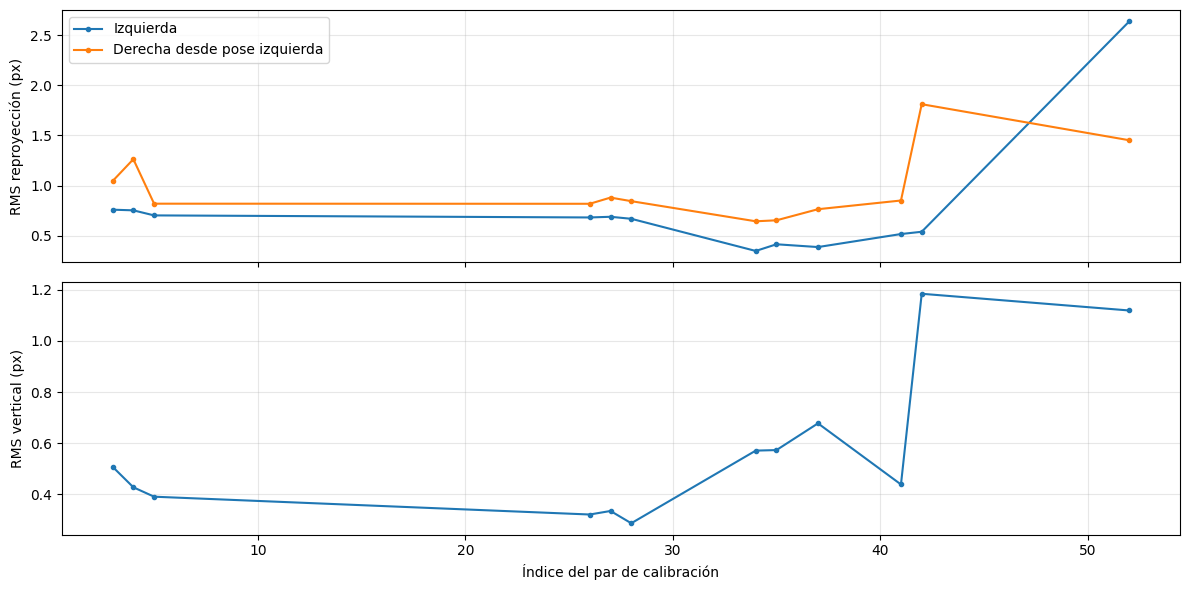

In [12]:
maps = calib_results["maps"]
diagnostics = calib_results["diagnostics"]

print_calibration_diagnostics(diagnostics, maps["P1"][0, 0], RECTIFICATION_ALPHA)
show_calibration_errors(
    diagnostics, save_path=REPORT_IMAGES_DIR / "errores_calibracion.png"
)

## 3. Ejemplo original y rectificado

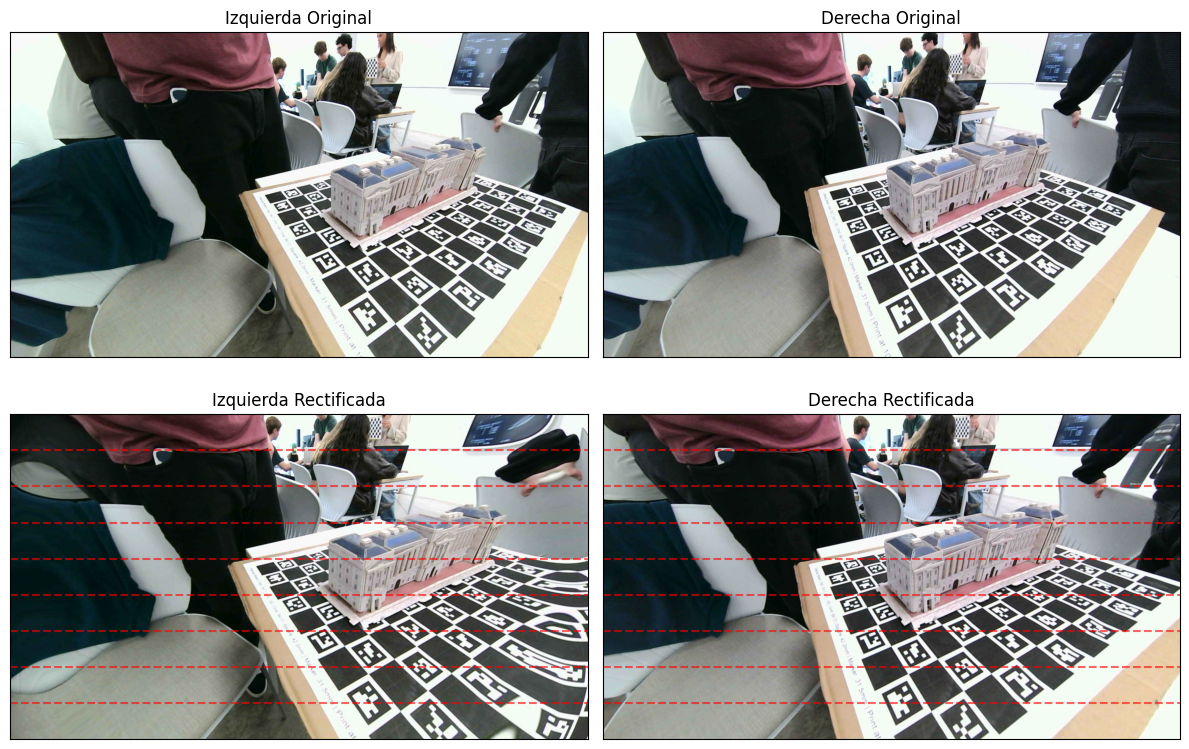

In [13]:
show_rectification_example(
    dataset_name="palacio",
    index=diagnostics["rows"][0]["pair_id"],
    maps=maps,
    image_size=image_size,
    save_path=REPORT_IMAGES_DIR / "rectificacion_palacio.png",
)

## 4. Guardar resultados

In [14]:
metadata = save_calibration_results(
    CALIBRATION_DIR,
    calib,
    maps,
    calibration_rms,
    calib_results["filtered_data"],
    diagnostics,
    root_dir=ROOT_DIR,
    rows=ROWS,
    cols=COLS,
    square_size_mm=SQUARE_SIZE_MM,
    rectification_alpha=RECTIFICATION_ALPHA,
)
print(
    f"Calibración, mapas y diagnóstico guardados en {CALIBRATION_DIR.relative_to(ROOT_DIR)}"
)

Calibración, mapas y diagnóstico guardados en data/calibration_results
